In [1]:
# load libraries
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import shape
# %pip install country_converter
import country_converter as coco
import pyogrio
pyogrio.list_drivers()

{'MEM': 'rw',
 'PCIDSK': 'raw',
 'PDS4': 'raw',
 'VICAR': 'rw',
 'PDF': 'w',
 'MBTiles': 'rw',
 'EEDA': 'r',
 'OGCAPI': 'r',
 'GDALG': 'r',
 'ESRI Shapefile': 'raw',
 'MapInfo File': 'raw',
 'LVBAG': 'r',
 'S57': 'rw',
 'DGN': 'rw',
 'OGR_VRT': 'r',
 'CSV': 'raw',
 'GML': 'rw',
 'GPX': 'rw',
 'LIBKML': 'raw',
 'KML': 'rw',
 'GeoJSON': 'raw',
 'GeoJSONSeq': 'raw',
 'ESRIJSON': 'r',
 'TopoJSON': 'r',
 'OGR_GMT': 'rw',
 'GPKG': 'raw',
 'SQLite': 'raw',
 'WAsP': 'rw',
 'OpenFileGDB': 'raw',
 'DXF': 'rw',
 'FlatGeobuf': 'rw',
 'GeoRSS': 'rw',
 'VFK': 'r',
 'PGDUMP': 'w',
 'OSM': 'r',
 'GPSBabel': 'rw',
 'OGR_PDS': 'r',
 'WFS': 'r',
 'OAPIF': 'r',
 'EDIGEO': 'r',
 'Idrisi': 'r',
 'ODS': 'raw',
 'XLSX': 'raw',
 'Elasticsearch': 'rw',
 'Carto': 'rw',
 'AmigoCloud': 'rw',
 'SXF': 'r',
 'Selafin': 'rw',
 'JML': 'rw',
 'PLSCENES': 'r',
 'CSW': 'r',
 'VDV': 'rw',
 'MVT': 'rw',
 'NGW': 'rw',
 'MapML': 'rw',
 'GTFS': 'r',
 'PMTiles': 'rw',
 'JSONFG': 'rw',
 'MiraMonVector': 'rw',
 'ADBC': 'r',
 'AVC

In [2]:
# load wold gdp data skipping 4 rows
gdp = pd.read_csv("/Data/GDP.csv", skiprows = 4)

# get most recent non NaN value for GDP
year_cols = [c for c in gdp.columns if c.isdigit()]
years = gdp[year_cols]

gdp["gdp_year"] = years.apply(pd.Series.last_valid_index, axis=1)
gdp["gdp_pc"] = years.ffill(axis=1).iloc[:, -1]

gdp_latest = gdp[["Country Name", "Country Code", "gdp_year", "gdp_pc"]]

# Denotes regions
meta = pd.read_csv("/Data/Metadata_Country_API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv")
real_countries = meta.loc[meta["Region"].notna(), "Country Code"]
gdp_latest = gdp_latest[gdp_latest["Country Code"].isin(real_countries)]

In [3]:
# load the population risk country data
pop = pd.read_csv("/Data/pop_at_risk_all.csv")

# applying the geometry
pop["geometry"] = pop[".geo"].apply(lambda g: shape(json.loads(g)))
gdf = gpd.GeoDataFrame(pop.drop(columns=".geo"), geometry="geometry", crs="EPSG:4326")
cols = ["country_na", "pop_risk_1m", "pop_risk_2m", "pop_risk_5m", "pop_total", "geometry"]
gdf = gdf[cols].dissolve(by="country_na", aggfunc="sum").reset_index()

In [4]:
# add ISO3 codes to the population/geometry data
# Parsing the geometries to properly merge the GDP and pop data
gdf["iso3"] = coco.convert(names=gdf["country_na"].tolist(), to="ISO3", not_found=None)
gdf.loc[gdf["country_na"] == "S Georgia & S Sandwich Is", "iso3"] = "SGS"

# give territories without a code a unique key so they aren't lumped together
gdf["iso3"] = gdf["iso3"].fillna(gdf["country_na"])

# combine pieces of the same country: merge shapes, sum populations
gdf = gdf.dissolve(
    by="iso3",
    aggfunc={
        "country_na": "first",
        "pop_risk_1m": "sum",
        "pop_risk_2m": "sum",
        "pop_risk_5m": "sum",
        "pop_total": "sum",
    },
).reset_index()

# tidy the one name that "first" picks oddly
gdf.loc[gdf["iso3"] == "PSE", "country_na"] = "Palestine"
gdf[gdf["iso3"].duplicated(keep=False) & gdf["iso3"].notna()][["country_na", "iso3"]]

merged = gdf.merge(gdp_latest, left_on="iso3", right_on="Country Code", how="left")
merged.loc[merged["gdp_pc"].isna(), ["country_na", "iso3"]]

Abyei Area not found in regex
Akrotiri not found in regex
Aksai Chin not found in regex
Ashmore & Cartier Is not found in regex
Bir Tawil not found in regex
Clipperton Island not found in regex
Coral Sea Is not found in regex
Demchok Area not found in regex
Dhekelia not found in regex
Dragonja River Mouth not found in regex
Dramana-Shakatoe Area not found in regex
French S & Antarctic Lands not found in regex
Halaib Triangle not found in regex
IN-CH Small Disputed Areas not found in regex
Invernada Area not found in regex
Isla Brasilera not found in regex
Jan Mayen not found in regex
Kalapani Area not found in regex
Korean Is. (UN Jurisdiction) not found in regex
Koualou Area not found in regex
Liancourt Rocks not found in regex
Navassa I not found in regex
No Man's Land not found in regex
Norfolk I not found in regex
Paracel Is not found in regex
More than one regular expression match for S Georgia & S Sandwich Is
More than one regular expression match for S Georgia & S Sandwich Is
Mo

,country_na,iso3
3,Anguilla,AIA
14,Abyei Area,Abyei Area
15,Akrotiri,Akrotiri
16,Aksai Chin,Aksai Chin
17,Ashmore & Cartier Is,Ashmore & Cartier Is
...,...,...
258,US Minor Pacific Is. Refuges,US Minor Pacific Is. Refuges
261,Vatican City,VAT
264,British Virgin Is,VGB
268,Wallis & Futuna,WLF


In [5]:
# load the sea level rise data
slr = pd.read_csv("/Data/slr_by_country.csv")
slr.head()

# drop geometry because it is the same from GEE
slr = slr.drop(columns=[".geo", "system:index"])

# same ISO3 steps as before
slr["iso3"] = coco.convert(names=slr["country_na"].tolist(), to="ISO3", not_found=None)
slr.loc[slr["country_na"] == "S Georgia & S Sandwich Is", "iso3"] = "SGS"
slr["iso3"] = slr["iso3"].fillna(slr["country_na"])

# one row per country: average the pieces
slr_cols = ["slr_ssp245_2050", "slr_ssp245_2100", "slr_ssp585_2050", "slr_ssp585_2100"]
slr_country = slr.groupby("iso3")[slr_cols].mean().reset_index()

# add to the dashboard data, converting mm to metres
merged = merged.merge(slr_country, on="iso3", how="left")
merged[slr_cols] = merged[slr_cols] / 1000

Koualou Area not found in regex
Bir Tawil not found in regex
Halaib Triangle not found in regex
Abyei Area not found in regex
Senkakus not found in regex
Korean Is. (UN Jurisdiction) not found in regex
Liancourt Rocks not found in regex
Dragonja River Mouth not found in regex
Jan Mayen not found in regex
Aksai Chin not found in regex
Siachen-Saltoro Area not found in regex
Demchok Area not found in regex
IN-CH Small Disputed Areas not found in regex
Kalapani Area not found in regex
Dramana-Shakatoe Area not found in regex
US Minor Pacific Is. Refuges not found in regex
Wake I not found in regex
Norfolk I not found in regex
Paracel Is not found in regex
Spratly Is not found in regex
Ashmore & Cartier Is not found in regex
Sinafir & Tiran Is. not found in regex
Dhekelia not found in regex
Akrotiri not found in regex
No Man's Land not found in regex
Coral Sea Is not found in regex
Navassa I not found in regex
More than one regular expression match for S Georgia & S Sandwich Is
More than o

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

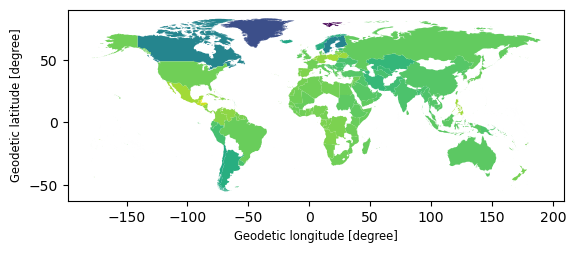

In [6]:
merged.loc[merged["pop_risk_5m"] == 0, slr_cols] = None
merged.plot(column = "slr_ssp245_2050")

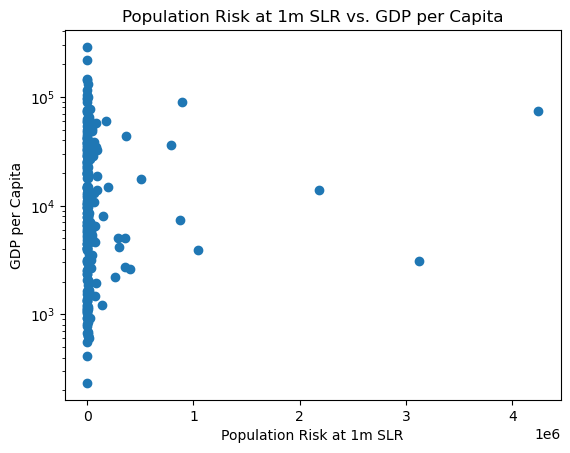

In [7]:
plt.scatter(merged.pop_risk_1m, merged.gdp_pc)
plt.title("Population Risk at 1m SLR vs. GDP per Capita")
plt.xlabel("Population Risk at 1m SLR")
plt.ylabel("GDP per Capita")
plt.yscale('log')
plt.show()

In [8]:
# calculating population at risk %
merged['pop_risk_1m_pct'] = merged.pop_risk_1m / merged.pop_total * 100
merged['pop_risk_2m_pct'] = merged.pop_risk_2m / merged.pop_total * 100
merged['pop_risk_5m_pct'] = merged.pop_risk_5m / merged.pop_total * 100

# removing dulicate country names
merged = merged.drop(columns=["country_na", "Country Code"]).rename(
    columns={"Country Name": "country"})

# accounts for countries without a coastline
merged["landlocked"] = merged["slr_ssp245_2100"].isna()

In [9]:
len(merged)

276

In [10]:
print("Duplicate iso3:", merged["iso3"].duplicated().sum())
print("No iso3:", merged["iso3"].isna().sum())
print("Zero population:", (merged["pop_total"] == 0).sum())

# See the duplicates side by side
dups = merged[merged["iso3"].duplicated(keep=False)]
print(dups[["iso3", "country", "pop_total"]].sort_values("iso3"))
merged = merged[merged["pop_total"] > 0]

Duplicate iso3: 0
No iso3: 0
Zero population: 17
Empty DataFrame
Columns: [iso3, country, pop_total]
Index: []


In [11]:
bad = merged[merged["iso3"].str.len() != 3]
print(len(bad))
print(bad[["iso3", "country", "pop_total"]])

merged = merged[merged["iso3"].str.len() == 3]
print(len(merged))   # should be about 240

print(merged.loc[merged["gdp_pc"].isna(), "country"].tolist())

19
                             iso3 country      pop_total
14                     Abyei Area     NaN  103029.761350
15                       Akrotiri     NaN    9684.593236
16                     Aksai Chin     NaN   11607.363987
39                      Bir Tawil     NaN     290.759149
69                   Demchok Area     NaN     748.899695
70                       Dhekelia     NaN   10010.640260
71           Dragonja River Mouth     NaN      33.347830
72          Dramana-Shakatoe Area     NaN      80.698738
111               Halaib Triangle     NaN   11004.868593
114    IN-CH Small Disputed Areas     NaN    1060.678294
123                Invernada Area     NaN     347.251452
138                 Kalapani Area     NaN      95.641534
139  Korean Is. (UN Jurisdiction)     NaN    4816.508727
140                  Koualou Area     NaN     709.393328
189                 No Man's Land     NaN   64656.070860
190                     Norfolk I     NaN    1825.159328
206                    Parac

In [12]:
short = merged.rename(columns={
    "slr_ssp245_2050": "s245_2050", "slr_ssp245_2100": "s245_2100",
    "slr_ssp585_2050": "s585_2050", "slr_ssp585_2100": "s585_2100",
    "pop_risk_1m": "risk_1m", "pop_risk_2m": "risk_2m", "pop_risk_5m": "risk_5m",})

short.to_file("SeaLevelRiseAnalysis.shp")

merged["geometry"] = merged.geometry.simplify(0.01)   # ~1 km tolerance
merged.to_crs(4326).to_file("SeaLevelRiseAnalysis.geojson", driver="GeoJSON")

/var/folders/f9/st5zr6ns55z298hrn9ljqcp80000gn/T/ipykernel_98645/3161679872.py:6: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  short.to_file("SeaLevelRiseAnalysis.shp")
/opt/anaconda3/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'pop_risk_1m_pct' to 'pop_risk_1'
  ogr_write(
/opt/anaconda3/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'pop_risk_2m_pct' to 'pop_risk_2'
  ogr_write(
/opt/anaconda3/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'pop_risk_5m_pct' to 'pop_risk_5'
  ogr_write(


In [13]:
# perform a correlation test between GDP and SLR
from scipy.stats import spearmanr

# select only costal countries and countries with GDPs
# coastal_countries = merged[~merged["landlocked"] & merged["gdp_pc"].notna()]
coastal_countries = merged[~merged["landlocked"] & merged["gdp_pc"].notna()].copy()
coastal_countries

# perform a spearman's rank correlation as it doesn't make as many assumptions (non-parametrey and relaxies normality)
results = []
for t in ["1m", "2m", "5m"]:
    rho, p = spearmanr(coastal_countries["gdp_pc"], coastal_countries[f"pop_risk_{t}_pct"])
    results.append({"threshold": t, "rho": round(rho, 2), "p_value": p,
                    "significant (p < 0.017)": p < 0.05 / 3, "n": len(coastal_countries)})

corr_table = pd.DataFrame(results)
corr_table.to_csv("spearmansrank_correlation.csv", index=False) 

# results implicate that the GDP per capital and the % of population at risk at 1m are correlated
# indicates a weak positive correlation where the higher the GDP per capital countries are the higher the population at risk at 1m SLR

In [14]:
# among the countries that are highly exposed, what does their wealtj look like 
# high exposure (top quarter at 1 m) split by wealth

#  find the top 25% of pop risk at 1
cutoff = coastal_countries["pop_risk_1m_pct"].quantile(0.75)
hi = coastal_countries[coastal_countries["pop_risk_1m_pct"] >= cutoff].copy()

# wealth based on metadata classification of income group
country_incomegroup = meta[["Country Code", "IncomeGroup"]]

coastal_countries = coastal_countries.merge(country_incomegroup, left_on="iso3", right_on="Country Code", how="left")

In [15]:
# exposure based on top 25% with highest population risk at 1%
coastal_countries["exposure"] = coastal_countries["pop_risk_1m_pct"].apply(lambda x: "High" if x >= cutoff else "Lower")

# wealth based on wealth based on metadata classification of income group
coastal_countries = coastal_countries.rename(columns = {"IncomeGroup": "wealth"})

# category combines exposure and wealth
coastal_countries["category"] = coastal_countries["exposure"] + " exposure, " + coastal_countries["wealth"]

# removes the second country code
coastal_countries = coastal_countries.drop('Country Code', axis=1)

# save as a geoJSON
coastal_countries.to_crs(4326).to_file("Coastal_Countries.geojson", driver="GeoJSON")

In [16]:
# filter for only landlocked countries
landlocked_countries = merged[merged["landlocked"] & merged["gdp_pc"].notna()].copy()

# creating same columns for landlocked countries
landlocked_countries = landlocked_countries.merge(country_incomegroup, left_on="iso3", right_on="Country Code", how="left")

# exposure should be say landlocked
landlocked_countries = landlocked_countries.copy()
landlocked_countries['exposure'] = "Landlocked"

# wealth still based on metadata classification of income group
landlocked_countries = landlocked_countries.rename(columns = {"IncomeGroup": "wealth"})

# category combines exposure and wealth
landlocked_countries["category"] = landlocked_countries["exposure"] + " exposure, " + landlocked_countries["wealth"]

# removes the second country code
landlocked_countries = landlocked_countries.drop('Country Code', axis=1)

# save as a geoJSON
landlocked_countries.to_crs(4326).to_file("Landlocked_Countries.geojson", driver="GeoJSON")

In [17]:
countries = pd.concat([coastal_countries, landlocked_countries])
countries.to_crs(4326).to_file("Countries.geojson", driver="GeoJSON")